# RT advantages seen so far — one summary figure (single cell)

Collects the RT effects found so far in genes and cell composition into one highlight figure.
Run after `psca_rt_figures.ipynb` (same folder), `code/mhcCytotoxExhaustion/` and `code/rtAdvantage/01`.

**Panels**
* **A / B — composition.** RT effect on each cell type's share of all cells, per CAR, in the irradiated
  (Tu1) and abscopal (Tu2) tumor. log2 (mean share with RT / mean share without RT); p = Welch t on log
  share (`p_prop` in `rtAdvantage/02`). Exact relabelling p are in the CSV; within one CAR they cannot
  go below 0.10 at 3 v 3.
* **C — CD8 T cells, irradiated tumor.** RT effect on the share of CD8 cells positive for each marker,
  per CAR and pooled (from `psca_rt_figures`, exact relabelling p).
* **D — genes where RT moves PSCA and TAG72 apart, irradiated tumor.** CAR × RT log2 fold change from the
  Tu1-only pydeseq2 fit (`~ car + rt + car:rt`); the number in each cell is its p.
* **E — scorecard.** Every finding, its strongest evidence, and its status:
  - **Holds:** p ≤ 0.05.
  - **Trend:** p < 0.10, or direction only.
  - **Caveat:** significant, but it moves with a tumor-wide immediate-early / NF-κB program (see
    `rtAdvantage/specificCellTypeAnalysis/01`, Figure M6).
  - **Against:** runs opposite to an RT advantage.
* **≈ in D:** the gene tracks that program from tumor to tumor within an arm (|r| ≥ 0.5).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, re
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/psca_rt_figures"
COMP = PROJ/"results/rt_advantage/composition_counts_fine.csv"
CD8E_CSV, PERSITE = OUT/"fig1_cd8_effects.csv", OUT/"persite_carxrt_de.parquet"
PROGS = PROJ/"results/mhc_cytotox/program_score_contrasts.csv"
MACDIR = PROJ/"results/rt_advantage/specific_cell_type/macrophages"     # optional: rtAdvantage/specificCellTypeAnalysis/01
for f_ in [COMP, CD8E_CSV, PERSITE, PROGS]:
    assert f_.exists(), f"missing {f_} — run psca_rt_figures.ipynb, mhcCytotoxExhaustion and rtAdvantage/01 first"

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72 = "#eb6834", "#2a78d6"
S_GOOD, S_WARN, S_CRIT = "#0ca30c", "#fab219", "#d03b3b"          # dataviz status palette (icon + label always)
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return f"{p:.3f}" if p < 0.1 else f"{p:.2f}"


def norm_arm(a): return str(a).replace("TAG72", "T72")

## 1. Composition: RT effect per cell type, CAR and site

In [2]:
cc = pd.read_csv(COMP).set_index("sample")
pct = cc.div(cc.sum(1), axis=0) * 100
meta = pd.DataFrame({"arm": [norm_arm(s.split("_Tu")[0]) for s in pct.index],
                     "site": [int(s.split("_Tu")[1][0]) for s in pct.index]}, index=pct.index)
ORDER = [("Myeloid", ["Classical_Mono", "Nonclassical_Mono", "Intermediate_Mac", "M1_like_Mac", "M2_like_Mac",
                      "cDC", "pDC", "N1_like_Neu", "N2_like_Neu"]),
         ("Lymphoid", ["CD8_T", "CD4_T", "Treg", "NK", "NKT", "B"]),
         ("Tumor / stroma", ["Cancer_cell", "Fibroblast", "Endothelial"])]
LAB = {"Classical_Mono": "Classical mono", "Nonclassical_Mono": "Non-classical mono", "Intermediate_Mac": "Intermediate mac",
       "M1_like_Mac": "M1-like mac", "M2_like_Mac": "M2-like mac", "N1_like_Neu": "N1 neutrophil",
       "N2_like_Neu": "N2 neutrophil", "CD8_T": "CD8 T", "CD4_T": "CD4 T", "Cancer_cell": "Tumor cells"}


def exact_p(a, b):
    x = np.r_[a, b]; k = len(a); obs = a.mean() - b.mean(); null = []
    for c in itertools.combinations(range(len(x)), k):
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    return float((np.abs(null) >= abs(obs) - 1e-12).mean())


rows = []
for site in (1, 2):
    for car, (rt_arm, no_arm) in {"PSCA": ("RTCyPSCA", "CyPSCA"), "TAG72": ("RTCyT72", "CyT72")}.items():
        a_ = pct[(meta.arm == rt_arm) & (meta.site == site)]; b_ = pct[(meta.arm == no_arm) & (meta.site == site)]
        for ct in pct.columns:
            if ct == "Erythrocyte": continue
            a, b = a_[ct].values, b_[ct].values
            la, lb = np.log(a + 1e-6), np.log(b + 1e-6)
            rows.append(dict(site=site, car=car, cell_type=ct, n_rt=len(a), n_no=len(b), pct_rt=a.mean(), pct_no=b.mean(),
                             log2fc=np.log2((a.mean() + 1e-3) / (b.mean() + 1e-3)),
                             p_welch_log=stats.ttest_ind(la, lb, equal_var=False).pvalue,
                             p_exact_log=exact_p(la, lb),
                             cells_rt=cc.loc[a_.index, ct].mean(), cells_no=cc.loc[b_.index, ct].mean()))
CE = pd.DataFrame(rows); CE.to_csv(OUT/"fig0_composition_rt_effects.csv", index=False)
print(CE[CE.p_welch_log < 0.10].round(3).to_string(index=False))

 site   car         cell_type  n_rt  n_no  pct_rt  pct_no  log2fc  p_welch_log  p_exact_log  cells_rt  cells_no
    1  PSCA       M1_like_Mac     3     3  27.816  20.200   0.462        0.059          0.1  1153.000   681.000
    1  PSCA       N1_like_Neu     3     3   0.501   2.267  -2.177        0.082          0.1    21.333    67.333
    1  PSCA Nonclassical_Mono     3     3   4.337   9.533  -1.136        0.046          0.1   171.667   295.333
    1  PSCA               pDC     3     3   0.205   0.405  -0.974        0.085          0.1     8.000    12.000
    1 TAG72               cDC     3     2   1.828   1.398   0.386        0.016          0.1    92.000    70.000
    2  PSCA  Intermediate_Mac     3     3  10.001   8.980   0.155        0.032          0.1   327.667   164.333


## 2. CD8, gene-level CAR × RT, and the program-level context

In [3]:
CD8E = pd.read_csv(CD8E_CSV)
PS = pd.read_parquet(PERSITE)
tu1 = PS[(PS.site == 1) & (PS.contrast == "CARxRT")].set_index(["group", "gene"])
MAC_G = ["IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "Classical_Mono"]
MAC_GENES = [("Nt5e", "CD73, adenosine"), ("Vegfa", "VEGF-A"), ("Il10", "IL-10"), ("Ciita", "MHC-II switch"),
             ("Pvr", "CD155: TIGIT / CD226 ligand"), ("Cd86", "co-stimulation"), ("Cd80", "co-stimulation"),
             ("Il1b", "IL-1β"), ("Cd274", "PD-L1")]
CD8_GENES = [("Nr4a1", "immediate-early gene"), ("Nr4a3", "immediate-early gene"), ("Klf2", "immediate-early / quiescence"),
             ("Cxcr6", "tissue residence"), ("Gzmk", "effector"), ("Pdcd1", "PD-1")]
GL = {"IFN_stimulated_Mac": "M1-like\n(IFN-stim)", "M2_like_Mac": "M2-like", "Intermediate_Mac": "Inter-\nmediate",
      "SPP1_TAM": "SPP1-\nTAM", "Classical_Mono": "Classical\nmono", "CD8_T": "CD8 T"}


def grab(group, gene, col): return tu1[col].get((group, gene), np.nan)


HM_mac = pd.DataFrame({g: [grab(g, x, "log2FoldChange") for x, _ in MAC_GENES] for g in MAC_G}, index=[x for x, _ in MAC_GENES])
HP_mac = pd.DataFrame({g: [grab(g, x, "pvalue") for x, _ in MAC_GENES] for g in MAC_G}, index=HM_mac.index)
HM_cd8 = pd.DataFrame({"CD8_T": [grab("CD8_T", x, "log2FoldChange") for x, _ in CD8_GENES]}, index=[x for x, _ in CD8_GENES])
HP_cd8 = pd.DataFrame({"CD8_T": [grab("CD8_T", x, "pvalue") for x, _ in CD8_GENES]}, index=HM_cd8.index)
# does each gene track the tumor-wide immediate-early (IEG) program from tumor to tumor within an arm? (Tu1)
PBc = pd.read_parquet(PROJ/"results/mhc_cytotox/pseudobulk_counts.parquet")
PBMc = pd.read_csv(PROJ/"results/mhc_cytotox/pseudobulk_meta.csv").set_index("key").loc[PBc.index]
PBMc["arm"] = PBMc.arm.map(norm_arm)
Lc = np.log2(PBc.div(PBc.sum(1), axis=0) * 1e6 + 1)
IEG_GENES = [g for g in ["Fos", "Fosb", "Jun", "Junb", "Jund", "Egr1", "Egr2", "Egr3", "Atf3", "Ier2", "Ier3", "Ier5", "Dusp1",
                         "Hspa1a", "Hspa1b", "Hspa8", "Hsp90aa1", "Hspb1", "Nr4a1", "Nr4a2", "Zfp36", "Klf2", "Klf4", "Klf6",
                         "Socs3", "Nfkbia", "Ppp1r15a", "Btg2", "Cebpd", "Gadd45b", "Ccn1", "Cyr61", "Rhob"] if g in Lc.columns]


def ieg_r(group, genes):
    d = PBMc[(PBMc.group == group) & (PBMc.n_cells >= 10) & (PBMc.arm != "NoTx")]
    Lg = Lc.loc[d.index]; ex = [g for g in IEG_GENES if Lg[g].mean() >= 1]
    sc = ((Lg[ex] - Lg[ex].mean()) / Lg[ex].std()).mean(1)
    t1 = (d.site == 1).values; arms_ = d.arm.values[t1]
    z = pd.Series(sc.values[t1]); zc = z - z.groupby(arms_).transform("mean")
    out = {}
    for g in genes:
        if g not in Lg.columns: out[g] = np.nan; continue
        y = pd.Series(Lg[g].values[t1]); yc = y - y.groupby(arms_).transform("mean")
        out[g] = float(np.corrcoef(yc, zc)[0, 1]) if yc.std() > 0 else np.nan
    return out


IR_mac = pd.DataFrame({g: ieg_r(g, [x for x, _ in MAC_GENES]) for g in MAC_G})
IR_cd8 = pd.DataFrame({"CD8_T": ieg_r("CD8_T", [x for x, _ in CD8_GENES])})
pd.concat([HM_mac.stack().rename("carxrt_log2fc"), HP_mac.stack().rename("p"), IR_mac.stack().rename("ieg_within_arm_r")], axis=1).to_csv(OUT/"fig0_mac_genes_carxrt_tu1.csv")
pd.concat([HM_cd8.stack().rename("carxrt_log2fc"), HP_cd8.stack().rename("p"), IR_cd8.stack().rename("ieg_within_arm_r")], axis=1).to_csv(OUT/"fig0_cd8_genes_carxrt_tu1.csv")

PG = pd.read_csv(PROGS)
ps_ifn = PG[(PG.effect == "PSCA") & (PG.family == "IFN") & (PG.p_main < 0.05)]
n_ifn_bigger = int(((np.sign(ps_ifn.d_RT) == np.sign(ps_ifn.main)) & (ps_ifn.d_RT.abs() > ps_ifn.d_nonRT.abs())).sum())
abs_isg = PG[(PG.effect == "indirect RT") & (PG.group == "IFN_stimulated_Mac") & (PG.program == "ISG_core")].iloc[0]
abs_cx = PG[(PG.effect == "indirect RT") & (PG.group == "IFN_stimulated_Mac") & (PG.program == "CXCR3_ligands")].iloc[0]
print(f"IFN programs bigger with RT: {n_ifn_bigger}/{len(ps_ifn)}; interaction p {ps_ifn.p_inter.min():.2f}-{ps_ifn.p_inter.max():.2f}")
print(f"abscopal ISG_core {abs_isg.main:+.2f} SD p {abs_isg.p_main}; CXCL9/10 {abs_cx.main:+.2f} p {abs_cx.p_main}")

IFN programs bigger with RT: 19/21; interaction p 0.14-0.86
abscopal ISG_core -1.32 SD p 0.005; CXCL9/10 -0.93 p 0.02


## 3. Scorecard (numbers pulled from the tables above)

In [4]:
d8 = CD8E[(CD8E.effect == "direct RT")].set_index(["marker", "part"])
def cd8(m, part="pooled", k="est"): return d8.loc[(m, part), k]


def ce(site, car, ct, k): return CE[(CE.site == site) & (CE.car == car) & (CE.cell_type == ct)][k].iloc[0]


p_cd8_genes = HP_cd8.loc[["Nr4a1", "Nr4a3", "Klf2", "Cxcr6"], "CD8_T"]
n_sig = (HP_mac < 0.05).sum(1)
p_supp = HP_mac.loc[["Nt5e", "Vegfa", "Il10"]].stack(); p_supp = p_supp[p_supp < 0.05]
supp_dn = {g: int(((HP_mac.loc[g] < 0.05) & (HM_mac.loc[g] < 0)).sum()) for g in ["Nt5e", "Vegfa", "Il10"]}
apoe_rt = cd8_ieg = None
if (MACDIR/"composition_effects.csv").exists():
    _c = pd.read_csv(MACDIR/"composition_effects.csv")
    _c = _c[(_c.feature == "Apoe_high") & (_c.denominator == "% of macrophages") & (_c.effect == "RT Tu1") & (_c.part == "pooled")]
    apoe_rt = _c.iloc[0] if len(_c) else None
if (MACDIR/"ieg_axis_effects.csv").exists():
    _i = pd.read_csv(MACDIR/"ieg_axis_effects.csv")
    _i = _i[(_i.group == "CD8_T") & (_i.effect == "RT Tu1") & (_i.part == "CARxRT")]
    cd8_ieg = _i.iloc[0] if len(_i) else None
p_mac_core = HP_mac.loc[["Pvr", "Cd86", "Cd80", "Ciita"]].stack()
p_mac_core = p_mac_core[p_mac_core < 0.05]
p_il1b, p_pdl1 = HP_mac.loc["Il1b"], HP_mac.loc["Cd274"]
il1b_dn, pdl1_dn = int((HM_mac.loc["Il1b"] < 0).sum()), int((HM_mac.loc["Cd274"] < 0).sum())
il1b_t = p_il1b[p_il1b < 0.10]

SCORE = [
    ("Holds", "CD8 T, irradiated tumor,\nboth CARs",
     f"More Gzmb+ ({cd8('Gzmb+'):+.0f} pp), Cxcr3+ ({cd8('Cxcr3+'):+.0f}), Ccr5+ ({cd8('Ccr5+'):+.0f});\n"
     f"fewer stem-like Tcf7+ ({cd8('Tcf7+'):+.0f})",
     f"p {fmt_p(min(cd8(m, k='p') for m in ['Gzmb+', 'Cxcr3+', 'Ccr5+', 'Tcf7+']))}–"
     f"{fmt_p(max(cd8(m, k='p') for m in ['Gzmb+', 'Cxcr3+', 'Ccr5+', 'Tcf7+']))}"),
    ("Holds", "Myeloid cells, PSCA only\n(CAR × RT)",
     f"CD73 (Nt5e) ↓ in {supp_dn['Nt5e']}/5 groups, VEGF-A ↓ {supp_dn['Vegfa']}/5,\nIL-10 ↓ {supp_dn['Il10']}/5; "
     "falls in PSCA, not a rise in TAG72",
     f"p {fmt_p(p_supp.min())}–{fmt_p(p_supp.max())}\n(VEGF-A, IL-10 ≈ IEG)"),
] + ([("Holds", "Apoe-high macrophages,\nirradiated, both CARs",
       f"{apoe_rt.est:+.2f} log2 share of macrophages\n(one global Apoe cut)", f"p {fmt_p(apoe_rt.p)} (exact, pooled)")]
     if apoe_rt is not None else []) + [
    ("Holds", "Non-classical monocytes,\nPSCA irradiated",
     f"{ce(1, 'PSCA', 'Nonclassical_Mono', 'pct_no'):.1f}% → {ce(1, 'PSCA', 'Nonclassical_Mono', 'pct_rt'):.1f}% of cells",
     f"p {fmt_p(ce(1, 'PSCA', 'Nonclassical_Mono', 'p_welch_log'))} (Welch)"),
    ("Caveat", "CD8 T, PSCA only\n(CAR × RT)",
     "Nr4a1, Nr4a3, Klf2 down; Cxcr6 up.\nNr4a1/3 and Klf2 are immediate-early genes",
     f"p {fmt_p(p_cd8_genes.min())}–{fmt_p(p_cd8_genes.max())}" + (f"\nCD8 IEG score p {fmt_p(cd8_ieg.p)}" if cd8_ieg is not None else "")),
    ("Caveat", "Macrophages, PSCA only\n(CAR × RT)",
     f"Pvr ↓ {n_sig['Pvr']}/5, Cd86 ↓ {n_sig['Cd86']}/5, Cd80 ↓ {n_sig['Cd80']}/5, Ciita ↑ {n_sig['Ciita']}/5;\n"
     "Ciita tracks IEG; others lose p after adjustment",
     f"p {fmt_p(p_mac_core.min())}–{fmt_p(p_mac_core.max())}"),
    ("Trend", "M1-like macrophages,\nPSCA irradiated",
     f"PSCA {ce(1, 'PSCA', 'M1_like_Mac', 'pct_no'):.1f}% → {ce(1, 'PSCA', 'M1_like_Mac', 'pct_rt'):.1f}%;\n"
     f"TAG72 {ce(1, 'TAG72', 'M1_like_Mac', 'pct_no'):.1f}% → {ce(1, 'TAG72', 'M1_like_Mac', 'pct_rt'):.1f}%",
     f"p {fmt_p(ce(1, 'PSCA', 'M1_like_Mac', 'p_welch_log'))} (Welch)"),
    ("Trend", "Macrophage Il1b and PD-L1,\nPSCA only",
     f"Il1b lower in {il1b_dn}/5 groups (tracks IEG);\nPD-L1 lower in {pdl1_dn}/5, direction only",
     f"Il1b p {fmt_p(il1b_t.min())}–{fmt_p(il1b_t.max())}\nPD-L1 p ≥ {fmt_p(p_pdl1.min())}"),
    ("Trend", "Macrophage IFN programs,\nPSCA",
     f"PSCA effect bigger with RT in {n_ifn_bigger}/{len(ps_ifn)} programs\n(direction only)",
     f"interaction p ≥ {fmt_p(ps_ifn.p_inter.min())}"),
    ("Against", "Abscopal tumor, both CARs",
     f"IFN-stim macs lose ISGs ({abs_isg.main:+.1f} SD)\nand Cxcl9/10 ({abs_cx.main:+.1f} SD)",
     f"p {fmt_p(abs_isg.p_main)} / {fmt_p(abs_cx.p_main)}"),
]
pd.DataFrame(SCORE, columns=["status", "where", "finding", "evidence"]).to_csv(OUT/"fig0_scorecard.csv", index=False)
for r in SCORE: print(" | ".join(r))

Holds | CD8 T, irradiated tumor,
both CARs | More Gzmb+ (+30 pp), Cxcr3+ (+13), Ccr5+ (+22);
fewer stem-like Tcf7+ (-20) | p 0.010–0.050
Holds | Myeloid cells, PSCA only
(CAR × RT) | CD73 (Nt5e) ↓ in 4/5 groups, VEGF-A ↓ 5/5,
IL-10 ↓ 3/5; falls in PSCA, not a rise in TAG72 | p 0.001–0.047
(VEGF-A, IL-10 ≈ IEG)
Holds | Apoe-high macrophages,
irradiated, both CARs | -0.67 log2 share of macrophages
(one global Apoe cut) | p 0.010 (exact, pooled)
Holds | Non-classical monocytes,
PSCA irradiated | 9.5% → 4.3% of cells | p 0.046 (Welch)
Caveat | CD8 T, PSCA only
(CAR × RT) | Nr4a1, Nr4a3, Klf2 down; Cxcr6 up.
Nr4a1/3 and Klf2 are immediate-early genes | p 0.005–0.035
CD8 IEG score p 0.070
Caveat | Macrophages, PSCA only
(CAR × RT) | Pvr ↓ 5/5, Cd86 ↓ 5/5, Cd80 ↓ 4/5, Ciita ↑ 3/5;
Ciita tracks IEG; others lose p after adjustment | p 0.001–0.039
Trend | M1-like macrophages,
PSCA irradiated | PSCA 20.2% → 27.8%;
TAG72 13.8% → 15.5% | p 0.059 (Welch)
Trend | Macrophage Il1b and PD-L1,
PSCA only 

## 4. Figure

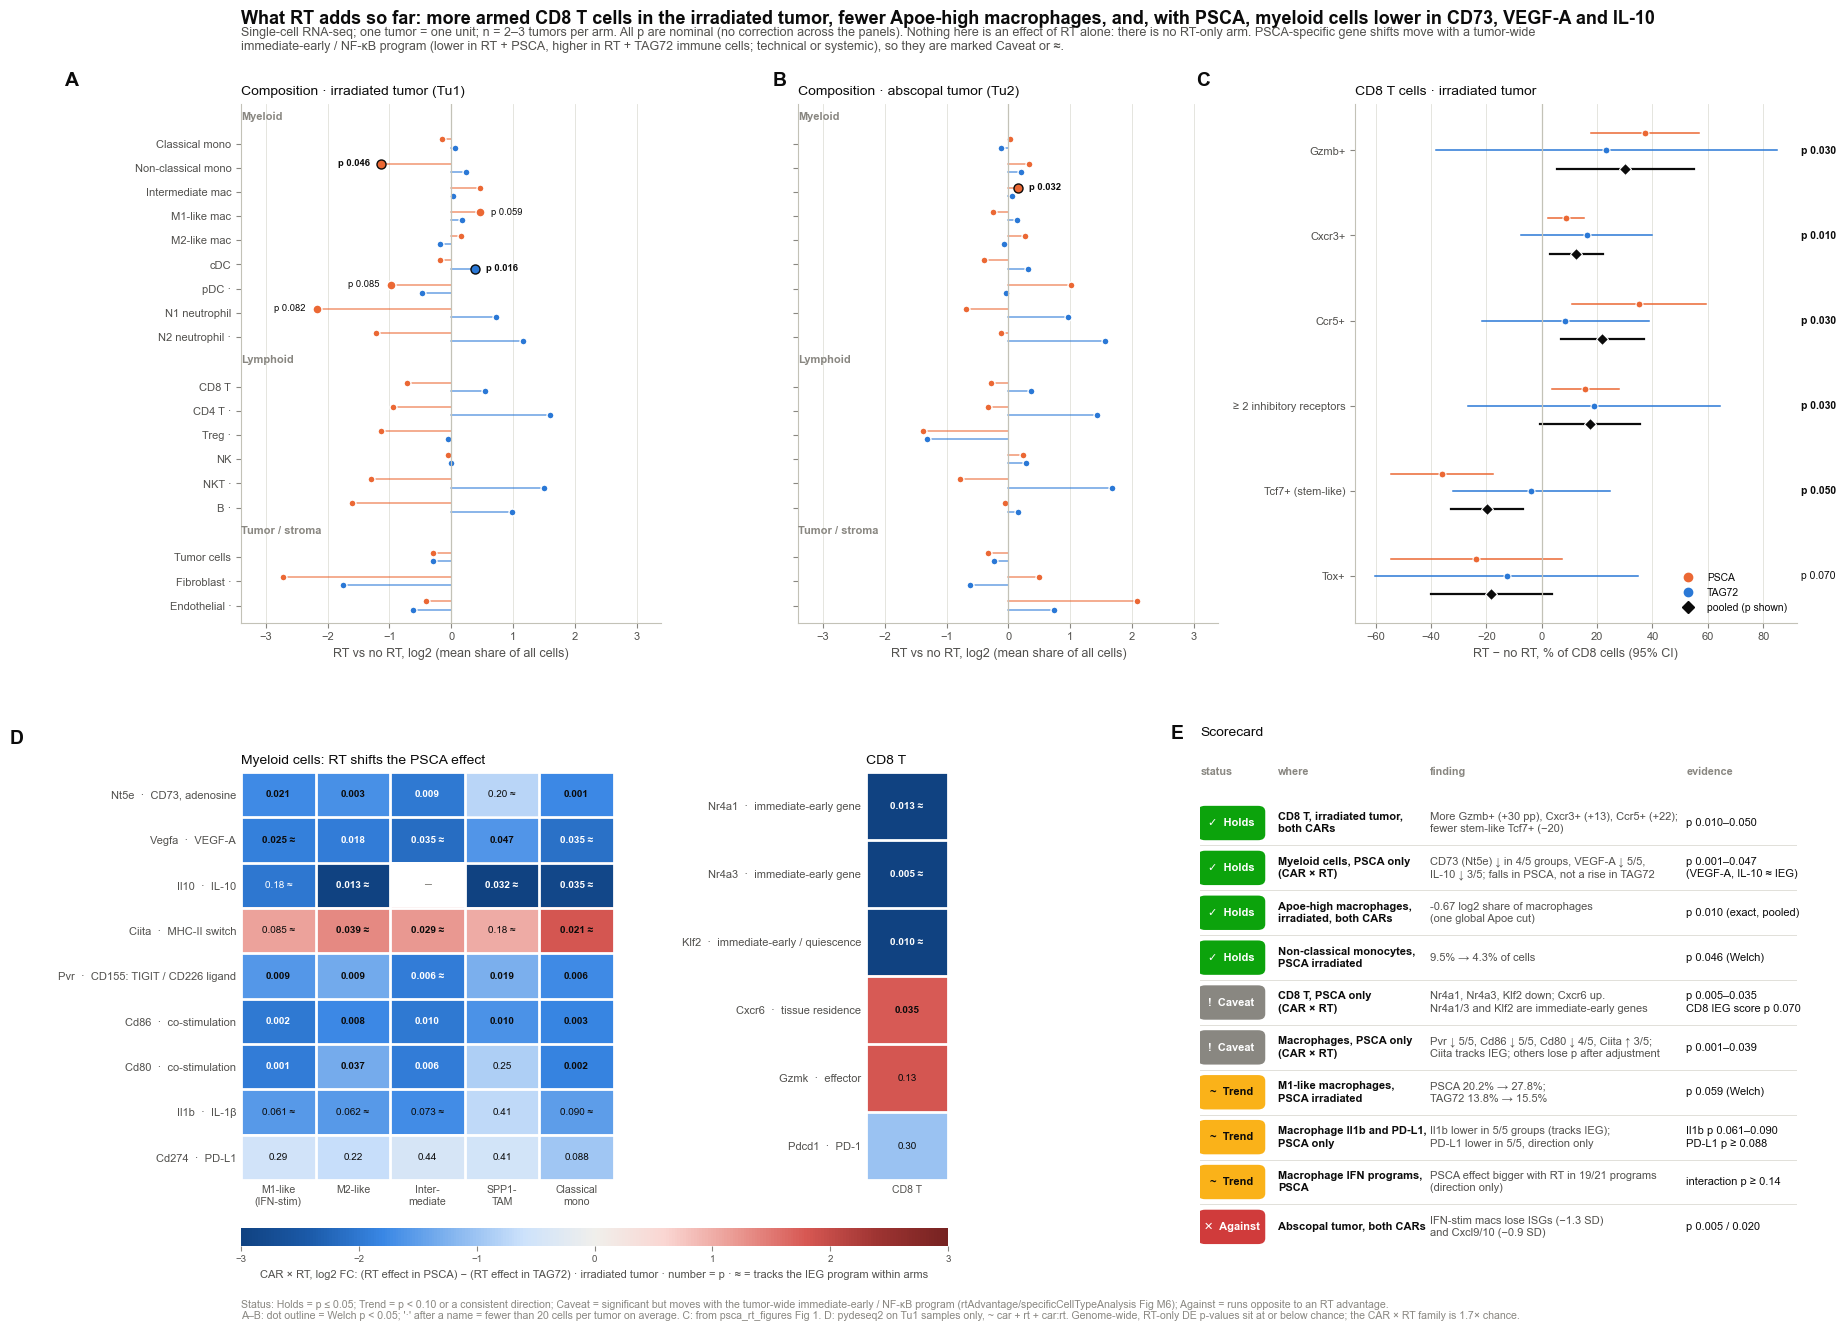

In [5]:
fig = plt.figure(figsize=(17, 13.4)) 
gs = GridSpec(2, 1, height_ratios=[1.0, 0.92], hspace=0.3, left=0.07, right=0.985, top=0.915, bottom=0.06)
fig.suptitle("What RT adds so far: more armed CD8 T cells in the irradiated tumor, fewer Apoe-high macrophages, and, "
             "with PSCA, myeloid cells lower in CD73, VEGF-A and IL-10",
             x=0.07, y=0.985, ha="left", fontsize=13, weight="bold")
fig.text(0.07, 0.955, "Single-cell RNA-seq; one tumor = one unit; n = 2–3 tumors per arm. All p are nominal (no "
         "correction across the panels). Nothing here is an effect of RT alone: there is no RT-only arm. PSCA-specific gene "
         "shifts move with a tumor-wide\nimmediate-early / NF-κB program (lower in RT + PSCA, higher in RT + TAG72 immune cells; "
         "technical or systemic), so they are marked Caveat or ≈.",
         fontsize=9, color=INK2)
top = GridSpecFromSubplotSpec(1, 3, gs[0], width_ratios=[1, 1, 1.05], wspace=0.32)


def comp_axis(ax, site, title, letter, show_labels):
    y, ticks, labs, heads = 0, [], [], []
    for grp, cts in ORDER:
        heads.append((y + 0.15, grp)); y -= 0.75
        for ct in cts:
            sparse = False
            for car, col, off in [("PSCA", C_PSCA, 0.17), ("TAG72", C_TAG72, -0.17)]:
                r = CE[(CE.site == site) & (CE.car == car) & (CE.cell_type == ct)].iloc[0]
                sparse |= min(r.cells_rt, r.cells_no) < 20
                lfc = float(np.clip(r.log2fc, -3, 3))
                ax.plot([0, lfc], [y + off] * 2, color=col, lw=1.4, alpha=0.55, solid_capstyle="round")
                ax.plot(lfc, y + off, "o", color=col, ms=6.5 if r.p_welch_log < 0.10 else 5,
                        mec=INK if r.p_welch_log < 0.05 else "white", mew=1.0)
                if r.p_welch_log < 0.10:
                    ax.text(lfc + (0.18 if lfc >= 0 else -0.18), y + off, f"p {fmt_p(r.p_welch_log)}", fontsize=6.8,
                            va="center", ha="left" if lfc >= 0 else "right", color=INK,
                            weight="bold" if r.p_welch_log < 0.05 else "normal")
            ticks.append(y); labs.append(LAB.get(ct, ct) + (" ·" if sparse else "")); y -= 1
        y -= 0.3
    for yy, g in heads:
        ax.text(-3.4, yy, g, fontsize=8, color=MUTED, weight="bold", va="bottom", ha="left")
    ax.axvline(0, color=AXIS, lw=0.9); ax.set_xlim(-3.4, 3.4); ax.set_ylim(y + 0.6, 0.9)
    ax.set_yticks(ticks); ax.set_yticklabels(labs if show_labels else [], fontsize=8)
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel("RT vs no RT, log2 (mean share of all cells)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.text(-0.42 if show_labels else -0.06, 1.035, letter, transform=ax.transAxes, fontsize=14, weight="bold")


ax1 = fig.add_subplot(top[0]); comp_axis(ax1, 1, "Composition · irradiated tumor (Tu1)", "A", True)
ax2 = fig.add_subplot(top[1]); comp_axis(ax2, 2, "Composition · abscopal tumor (Tu2)", "B", False)

# C: CD8 forest
ax = fig.add_subplot(top[2]); ax.text(-0.36, 1.035, "C", transform=ax.transAxes, fontsize=14, weight="bold")
MK = [("Gzmb+", "Gzmb+"), ("Cxcr3+", "Cxcr3+"), ("Ccr5+", "Ccr5+"), ("IR_ge2", "≥ 2 inhibitory receptors"),
      ("Tcf7+", "Tcf7+ (stem-like)"), ("Tox+", "Tox+")]
for i, (m, lab) in enumerate(MK):
    y = -i
    for part, col, off, mk in [("PSCA", C_PSCA, 0.2, "o"), ("TAG72", C_TAG72, 0.0, "o"), ("pooled", INK, -0.22, "D")]:
        r = d8.loc[(m, part)]
        ax.plot([r.lo, r.hi], [y + off] * 2, color=col, lw=1.6 if part == "pooled" else 1.1)
        ax.plot(r.est, y + off, marker=mk, color=col, ms=6 if part == "pooled" else 5, mec="white", mew=0.8)
    ax.text(1.01, y, f"p {fmt_p(d8.loc[(m, 'pooled'), 'p'])}", transform=ax.get_yaxis_transform(), fontsize=7.5,
            va="center", color=INK, weight="bold" if d8.loc[(m, 'pooled'), 'p'] <= 0.05 else "normal")
ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks([-i for i in range(len(MK))]); ax.set_yticklabels([l for _, l in MK])
ax.set_ylim(-len(MK) + 0.45, 0.55); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("RT − no RT, % of CD8 cells (95% CI)")
ax.set_title("CD8 T cells · irradiated tumor", loc="left", fontsize=10)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_PSCA, label="PSCA"),
                   Line2D([], [], marker="o", ls="", color=C_TAG72, label="TAG72"),
                   Line2D([], [], marker="D", ls="", color=INK, label="pooled (p shown)")],
          loc="lower right", frameon=False, fontsize=7.5)

# D: gene heatmaps
bot = GridSpecFromSubplotSpec(1, 3, gs[1], width_ratios=[1.0, 0.22, 1.6], wspace=0.72)
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)


def heat(ax, M, P, genes, glabels, title, IRM=None):
    im = ax.imshow(M.values.astype(float), cmap=DIV, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v, p = M.iat[i, j], P.iat[i, j]
            if not np.isfinite(v): ax.text(j, i, "–", ha="center", va="center", color=MUTED); continue
            r_ = IRM.iat[i, j] if IRM is not None else np.nan
            ax.text(j, i, fmt_p(p) + (" ≈" if np.isfinite(r_) and abs(r_) >= 0.5 else ""), ha="center", va="center", fontsize=7.2,
                    color="white" if abs(v) > 1.9 else INK, weight="bold" if p < 0.05 else "normal")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([GL[c] for c in M.columns], fontsize=7.6)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([f"{g}  ·  {d}" for g, d in genes], fontsize=8)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_xticks(np.arange(-.5, M.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, M.shape[0]), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
    ax.set_title(title, loc="left", fontsize=10)
    return im


axh = fig.add_subplot(bot[0])
im = heat(axh, HM_mac, HP_mac, MAC_GENES, None, "Myeloid cells: RT shifts the PSCA effect", IRM=IR_mac.reindex(HM_mac.index))
axh.text(-0.62, 1.07, "D", transform=axh.transAxes, fontsize=14, weight="bold")
axc = fig.add_subplot(bot[1]); heat(axc, HM_cd8, HP_cd8, CD8_GENES, None, "CD8 T", IRM=IR_cd8.reindex(HM_cd8.index))
cb = fig.colorbar(im, ax=[axh, axc], orientation="horizontal", fraction=0.045, pad=0.1, aspect=40)
cb.set_label("CAR × RT, log2 FC: (RT effect in PSCA) − (RT effect in TAG72) · irradiated tumor · number = p · "
             "≈ = tracks the IEG program within arms",
             fontsize=8, color=INK2)
cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7)

# E: scorecard
axs = fig.add_subplot(bot[2]); axs.axis("off")
axs.text(-0.05, 1.07, "E", transform=axs.transAxes, fontsize=14, weight="bold")
axs.text(0.0, 1.07, "Scorecard", transform=axs.transAxes, fontsize=10, va="bottom")
ICON = {"Holds": ("✓", S_GOOD, "white"), "Trend": ("~", S_WARN, INK), "Caveat": ("!", MUTED, "white"),
        "Against": ("✕", S_CRIT, "white")}
cols_x = [0.0, 0.13, 0.385, 0.815]
for x, h in zip(cols_x, ["status", "where", "finding", "evidence"]):
    axs.text(x, 1.0, h, transform=axs.transAxes, fontsize=7.8, color=MUTED, weight="bold", va="center")
n = len(SCORE); dy = 0.94 / n
for i, (st, where, finding, ev) in enumerate(SCORE):
    y = 0.94 - (i + 0.5) * dy
    ic, fc, tc = ICON[st]
    axs.add_patch(mpl.patches.FancyBboxPatch((cols_x[0], y - 0.032), 0.105, 0.064, boxstyle="round,pad=0.004,rounding_size=0.012",
                                             transform=axs.transAxes, facecolor=fc, edgecolor="none"))
    axs.text(cols_x[0] + 0.0525, y, f"{ic}  {st}", transform=axs.transAxes, ha="center", va="center", fontsize=8,
             color=tc, weight="bold")
    axs.text(cols_x[1], y, where, transform=axs.transAxes, va="center", fontsize=8, color=INK, weight="bold", linespacing=1.3)
    axs.text(cols_x[2], y, re.sub(r"(?<=[\s(])-(?=\d)", "−", finding), transform=axs.transAxes, va="center", fontsize=8, color=INK2, linespacing=1.3)
    axs.text(cols_x[3], y, ev, transform=axs.transAxes, va="center", fontsize=8, color=INK, linespacing=1.3)
    if i: axs.plot([0.0, 1.0], [y + dy / 2] * 2, transform=axs.transAxes, color=GRID, lw=0.7)

fig.text(0.07, 0.008, "Status: Holds = p ≤ 0.05; Trend = p < 0.10 or a consistent direction; Caveat = significant but moves with the "
         "tumor-wide immediate-early / NF-κB program (rtAdvantage/specificCellTypeAnalysis Fig M6); Against = runs opposite to an RT advantage.\n"
         "A–B: dot outline = Welch p < 0.05; '·' after a name = fewer than 20 cells per tumor on average. C: from psca_rt_figures Fig 1. "
         "D: pydeseq2 on Tu1 samples only, ~ car + rt + car:rt. Genome-wide, RT-only DE p-values sit at or below chance; the CAR × RT family is 1.7× chance.",
         fontsize=7.6, color=MUTED)
for ext in ("png", "pdf"): fig.savefig(OUT/f"Figure0_RT_advantage_summary.{ext}", bbox_inches="tight")
plt.show()

In [6]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
for r in SCORE: print(f"[{r[0]:7s}] {r[1]}: {r[2]}  ({r[3]})")
print("\n[composition, Welch p < 0.10]")
print(CE[CE.p_welch_log < 0.10][["site", "car", "cell_type", "pct_no", "pct_rt", "log2fc", "p_welch_log", "p_exact_log"]]
      .round(3).to_string(index=False))
print(f"\n[files] {OUT}/Figure0_RT_advantage_summary.png/.pdf, fig0_*.csv")
print("=" * 100)

SUMMARY — report these back
[Holds  ] CD8 T, irradiated tumor,
both CARs: More Gzmb+ (+30 pp), Cxcr3+ (+13), Ccr5+ (+22);
fewer stem-like Tcf7+ (-20)  (p 0.010–0.050)
[Holds  ] Myeloid cells, PSCA only
(CAR × RT): CD73 (Nt5e) ↓ in 4/5 groups, VEGF-A ↓ 5/5,
IL-10 ↓ 3/5; falls in PSCA, not a rise in TAG72  (p 0.001–0.047
(VEGF-A, IL-10 ≈ IEG))
[Holds  ] Apoe-high macrophages,
irradiated, both CARs: -0.67 log2 share of macrophages
(one global Apoe cut)  (p 0.010 (exact, pooled))
[Holds  ] Non-classical monocytes,
PSCA irradiated: 9.5% → 4.3% of cells  (p 0.046 (Welch))
[Caveat ] CD8 T, PSCA only
(CAR × RT): Nr4a1, Nr4a3, Klf2 down; Cxcr6 up.
Nr4a1/3 and Klf2 are immediate-early genes  (p 0.005–0.035
CD8 IEG score p 0.070)
[Caveat ] Macrophages, PSCA only
(CAR × RT): Pvr ↓ 5/5, Cd86 ↓ 5/5, Cd80 ↓ 4/5, Ciita ↑ 3/5;
Ciita tracks IEG; others lose p after adjustment  (p 0.001–0.039)
[Trend  ] M1-like macrophages,
PSCA irradiated: PSCA 20.2% → 27.8%;
TAG72 13.8% → 15.5%  (p 0.059 (Welch))
[Tren